# Stage 9: Shortage Detection and Recommendation Engine
## Hospital Resource Intelligence and Optimization Platform

This notebook loads the operational XGBoost demand forecasts, compares them against configurable available resource capacities, detects potential shortage risk levels, and generates actionable, non-clinical recommendations.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath('../ml/decision_engine'))
import thresholds

sns.set_theme(style='whitegrid')
ALERTS_CSV = '../outputs/alerts/resource_alerts.csv'
RECS_CSV = '../outputs/recommendations/recommendations.csv'
print('Dependencies loaded successfully.')

Dependencies loaded successfully.


## 1. Load Resource Alerts and Recommendations
We load the generated shortage alerts and structured recommendations.

In [2]:
df_alerts = pd.read_csv(ALERTS_CSV)
df_recs = pd.read_csv(RECS_CSV)

print('Generated alerts dataset dimension:', df_alerts.shape)
print('Generated recommendations dataset dimension:', df_recs.shape)

Generated alerts dataset dimension: (14, 7)
Generated recommendations dataset dimension: (14, 6)


In [3]:
print('Shortage Alerts Table:')
df_alerts

Shortage Alerts Table:


,date,resource,predicted_demand,available_capacity,capacity_gap,risk_level,reason
0,2137-10-11,ICU Beds,0.204068,2.0,1.795932,LOW,Predicted demand is within safe capacity bounds.
1,2137-10-12,ICU Beds,0.237025,2.0,1.762975,LOW,Predicted demand is within safe capacity bounds.
2,2137-10-13,ICU Beds,0.450478,2.0,1.549522,LOW,Predicted demand is within safe capacity bounds.
3,2137-10-14,ICU Beds,0.353222,2.0,1.646778,LOW,Predicted demand is within safe capacity bounds.
4,2137-10-15,ICU Beds,0.285966,2.0,1.714034,LOW,Predicted demand is within safe capacity bounds.
5,2137-10-16,ICU Beds,0.428090,2.0,1.571910,LOW,Predicted demand is within safe capacity bounds.
6,2137-10-17,ICU Beds,0.291041,2.0,1.708959,LOW,Predicted demand is within safe capacity bounds.
7,2148-01-19,ED Arrivals,0.008455,2.0,1.991545,LOW,ED arrivals predicted within standard baseline...
8,2148-01-20,ED Arrivals,0.015088,2.0,1.984912,LOW,ED arrivals predicted within standard baseline...
9,2148-01-21,ED Arrivals,0.010670,2.0,1.989330,LOW,ED arrivals predicted within standard baseline...


In [4]:
print('Resource-Management Recommendations Table:')
df_recs

Resource-Management Recommendations Table:


,date,resource,risk_level,recommendation,trigger,model
0,2137-10-11,ICU Beds,LOW,Current predicted demand is within available c...,Predicted demand matches safe operational thre...,XGBoost
1,2137-10-12,ICU Beds,LOW,Current predicted demand is within available c...,Predicted demand matches safe operational thre...,XGBoost
2,2137-10-13,ICU Beds,LOW,Current predicted demand is within available c...,Predicted demand matches safe operational thre...,XGBoost
3,2137-10-14,ICU Beds,LOW,Current predicted demand is within available c...,Predicted demand matches safe operational thre...,XGBoost
4,2137-10-15,ICU Beds,LOW,Current predicted demand is within available c...,Predicted demand matches safe operational thre...,XGBoost
5,2137-10-16,ICU Beds,LOW,Current predicted demand is within available c...,Predicted demand matches safe operational thre...,XGBoost
6,2137-10-17,ICU Beds,LOW,Current predicted demand is within available c...,Predicted demand matches safe operational thre...,XGBoost
7,2148-01-19,ED Arrivals,LOW,Current predicted demand is within available c...,Predicted demand matches safe operational thre...,XGBoost
8,2148-01-20,ED Arrivals,LOW,Current predicted demand is within available c...,Predicted demand matches safe operational thre...,XGBoost
9,2148-01-21,ED Arrivals,LOW,Current predicted demand is within available c...,Predicted demand matches safe operational thre...,XGBoost


## 2. Visualizing ICU Bed Capacity Gaps
We plot the predicted ICU bed occupancy against the configured available bed capacity limit (2.0 beds) to see how close we are to a shortage.

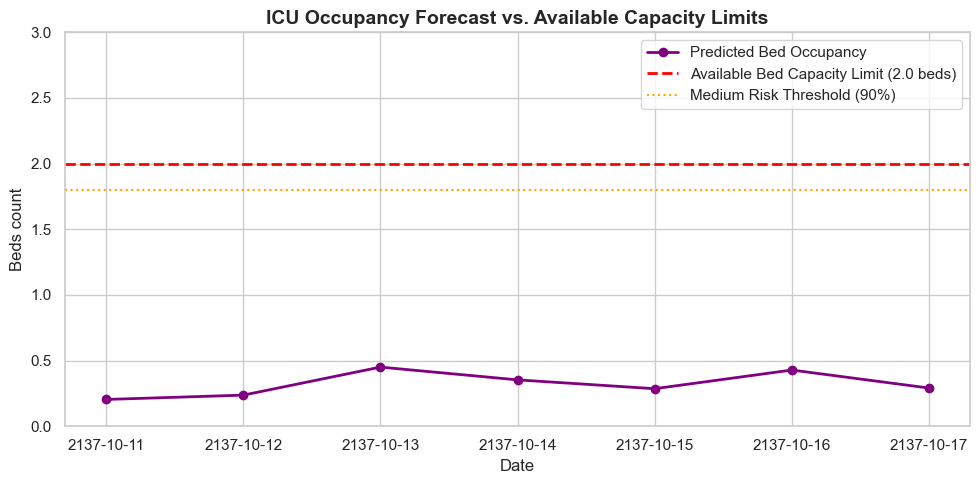

In [5]:
df_icu = df_alerts[df_alerts['resource'] == 'ICU Beds'].copy()
df_icu['date'] = pd.to_datetime(df_icu['date'])

plt.figure(figsize=(10, 5))
plt.plot(df_icu['date'], df_icu['predicted_demand'], label='Predicted Bed Occupancy', color='purple', marker='o', linewidth=2)
plt.axhline(y=thresholds.ICU_CAPACITY, color='red', linestyle='--', label='Available Bed Capacity Limit (2.0 beds)', linewidth=2)
plt.axhline(y=thresholds.ICU_CAPACITY * thresholds.ICU_MEDIUM_PCT, color='orange', linestyle=':', label='Medium Risk Threshold (90%)', linewidth=1.5)
plt.title('ICU Occupancy Forecast vs. Available Capacity Limits', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Beds count')
plt.ylim(0, 3)
plt.legend()
plt.tight_layout()
plt.show()

## 3. Visualizing ED Arrivals Demand Pressure
We plot the predicted ED arrivals against the historical baseline (2.0 arrivals) and the pressure threshold multiplier (2.4 arrivals).

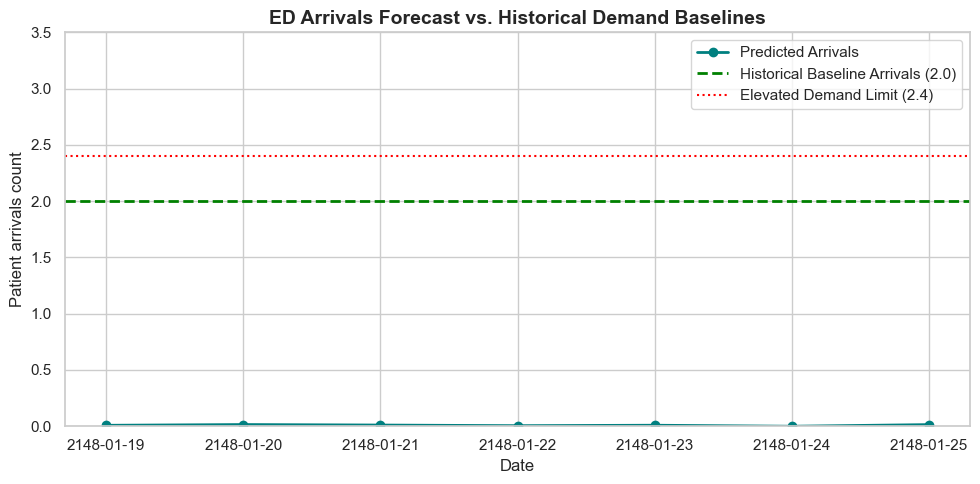

In [6]:
df_ed = df_alerts[df_alerts['resource'] == 'ED Arrivals'].copy()
df_ed['date'] = pd.to_datetime(df_ed['date'])

plt.figure(figsize=(10, 5))
plt.plot(df_ed['date'], df_ed['predicted_demand'], label='Predicted Arrivals', color='teal', marker='o', linewidth=2)
plt.axhline(y=thresholds.ED_BASELINE, color='green', linestyle='--', label='Historical Baseline Arrivals (2.0)', linewidth=2)
plt.axhline(y=thresholds.ED_BASELINE * thresholds.ED_THRESHOLD_MULT, color='red', linestyle=':', label='Elevated Demand Limit (2.4)', linewidth=1.5)
plt.title('ED Arrivals Forecast vs. Historical Demand Baselines', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Patient arrivals count')
plt.ylim(0, 3.5)
plt.legend()
plt.tight_layout()
plt.show()

## 4. Academic Interpretation
1. **Distinction between Forecasting, Alerting, and Recommendations**:
   - **Forecasting** (Stage 5/6) outputs the predicted resource demand $\hat{y}_t$ based on historical patterns.
   - **Shortage Detection** (Stage 9) evaluates $\hat{y}_t$ relative to capacity limits to assign operational risk boundaries.
   - **Recommendations** (Stage 9) generates logistical advice (staff allocations, bed shifts) to resolve potential gaps.
2. **Strict Non-Clinical Bounds**:
   - The recommendations are limited to operational resource management. There are no pharmaceutical, diagnostics, or therapeutic recommendations, maintaining compliance with safety rules.
3. **Explainability Connection**:
   - If a risk level changes to HIGH or MEDIUM, the trigger lists the top SHAP features, giving hospital administrators transparency on why the forecasting model made the underlying prediction.